In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

In [8]:
d = pd.read_csv("../data/Ad_table.csv")

C:\Users\jchmo\AppData\Local\Temp\ipykernel_58768\288108269.py:1: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv("../data/Ad_table.csv")


In [9]:
d["car_age"] = d["Adv_year"] - d["Reg_year"]
for c in ["Price", "Runned_Miles", "Engin_size"]:
    d[c] = pd.to_numeric(d[c].astype(str).str.extract(r"([\d.]+)")[0], errors="coerce")

In [10]:
d = d[d["car_age"].between(0, 15) & (d["Price"] > 500) & d["Runned_Miles"].between(0, 200_000)]
d = d[~d["Genmodel"].isin(["Z3M", "Z4M", "Z8"])]

In [11]:
cat_cols = ["Genmodel", "Fuel_type", "Gearbox", "Bodytype", "Color"]
num_cols = ["car_age", "Runned_Miles", "Engin_size", "Adv_year"]

R²: 0.955
Median abs error (£): 921


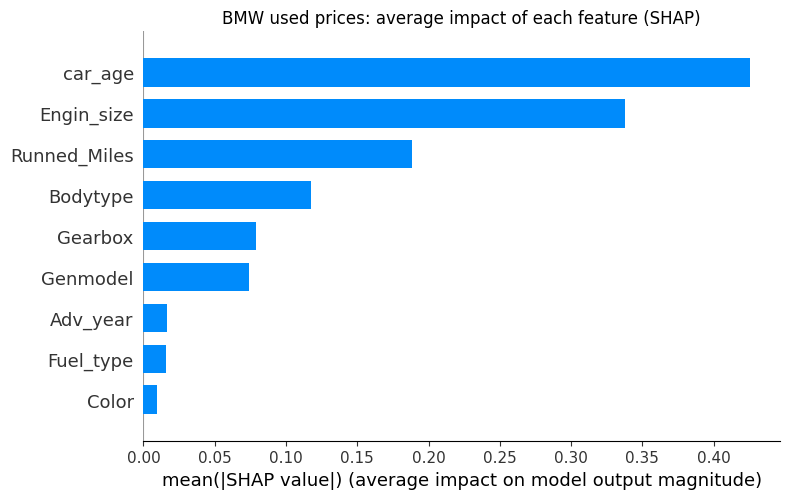

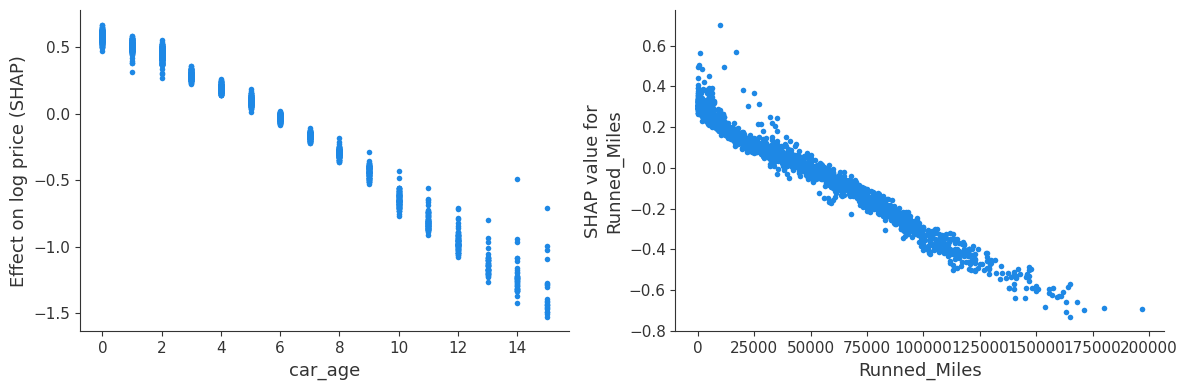

In [16]:
d = d[cat_cols + num_cols + ["Price"]].dropna()
for c in cat_cols:
    d[c] = d[c].astype(str).str.strip().astype("category").cat.codes   # simple integer encoding

X = d[cat_cols + num_cols]
y = np.log(d["Price"])

# --- 2. Train / test split + model ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.05,
                     subsample=0.8, colsample_bytree=0.8, random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("R²:", round(r2_score(y_test, pred), 3))
print("Median abs error (£):", round(np.median(np.abs(np.exp(pred) - np.exp(y_test)))))

# --- 3. SHAP values computed by XGBoost itself ---
sample = X_test.sample(min(2000, len(X_test)), random_state=42)
contribs = model.get_booster().predict(xgb.DMatrix(sample), pred_contribs=True)
shap_values = contribs[:, :-1]          # last column is the bias term, drop it

shap.summary_plot(shap_values, sample, plot_type="bar", show=False)
plt.title("BMW used prices: average impact of each feature (SHAP)")
plt.tight_layout()
plt.savefig("../images/bmw_shap_importance.png", dpi=150)
plt.show()

# --- 4. How age and mileage move the price ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
shap.dependence_plot("car_age", shap_values, sample, interaction_index=None, ax=axes[0], show=False)
shap.dependence_plot("Runned_Miles", shap_values, sample, interaction_index=None, ax=axes[1], show=False)
axes[0].set_ylabel("Effect on log price (SHAP)")
plt.tight_layout()
plt.savefig("../images/bmw_shap_age_miles.png", dpi=150)
plt.show()